# Preparação YOLO — RodoSol

Converter as anotações para detecção de uma única classe `placa`, preservando as divisões oficiais 40/20/40. A decisão está em [Estratégia de treinamento](../docs/3_estrategia_inicial_treinamento.md).

Este notebook é independente dos notebooks de análise. Grava somente imagens, labels e YAML em `datasets_yolo`. Não altera os brutos nem inicia treinamento. Reexecutar valida/reutiliza imagens existentes e atualiza labels e caminhos YAML. Execute as células em ordem; a cópia e a comparação de bytes podem demorar alguns minutos.


### 1. Onde estão a origem e o destino?

Localizamos o projeto automaticamente e usamos as bibliotecas já disponíveis no ambiente.


In [1]:
from pathlib import Path
from collections import Counter
import filecmp
import shutil
import math
import json
import numpy as np
import yaml
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

raiz = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "datasets_brutos").is_dir()), None)
if raiz is None:
    raise FileNotFoundError("Execute o notebook na raiz do projeto ou em src.")
DIVISOES = ("training", "validation", "testing")

nome = 'RodoSol'
origem = raiz / "datasets_brutos" / 'tbFcZE-RodoSol-ALPR'
destino = raiz / "datasets_yolo" / nome
esperados = {'training': 8000, 'validation': 4000, 'testing': 8000}
print("Origem:", origem)
print("Destino:", destino)


Origem: C:\Users\igorm\Documents\programacao\modelo-placa\datasets_brutos\tbFcZE-RodoSol-ALPR
Destino: C:\Users\igorm\Documents\programacao\modelo-placa\datasets_yolo\RodoSol


### 2. Quais arquivos pertencem a cada divisão?

UFPR usa as pastas oficiais; RodoSol usa o manifesto split.txt. Os caminhos relativos preservam tracks/grupos e evitam colisões de nomes.


In [2]:
# Montar a lista de arquivos antes de gravar qualquer imagem ou label.
registros = []
if nome == "UFPR":
    for divisao in DIVISOES:
        pasta = origem / divisao
        for imagem in sorted(pasta.rglob("*.png")):
            registros.append({"imagem": imagem, "divisao": divisao,
                              "relativo": imagem.relative_to(origem)})
    anotacoes = {p.relative_to(origem).with_suffix("").as_posix()
                 for d in DIVISOES for p in (origem / d).rglob("*.txt")}
else:
    vistos = set()
    for numero, linha in enumerate((origem / "split.txt").read_text(encoding="utf-8-sig").splitlines(), 1):
        if not linha.strip():
            continue
        partes = linha.strip().split(";")
        if len(partes) != 2:
            raise ValueError(f"Linha {numero} inválida no split.txt")
        caminho, divisao = partes
        rel = Path(caminho)
        if rel.is_absolute() or ".." in rel.parts or len(rel.parts) != 3 or rel.parts[0] != "images":
            raise ValueError(f"Caminho inesperado: {caminho}")
        if divisao not in DIVISOES or rel.as_posix() in vistos:
            raise ValueError(f"Divisão inválida ou caminho repetido na linha {numero}")
        vistos.add(rel.as_posix())
        registros.append({"imagem": origem / rel, "divisao": divisao,
                          "relativo": Path(divisao) / rel.relative_to("images")})
    existentes = {p.relative_to(origem).as_posix() for p in (origem / "images").rglob("*.jpg")}
    if existentes != vistos:
        raise ValueError(f"Manifesto difere dos arquivos: {len(existentes - vistos)} fora do manifesto; {len(vistos - existentes)} ausentes")
    anotacoes = {p.relative_to(origem).with_suffix("").as_posix() for p in (origem / "images").rglob("*.txt")}

imagens = {r["imagem"].relative_to(origem).with_suffix("").as_posix() for r in registros}
if imagens != anotacoes:
    raise ValueError(f"Pares ausentes: {len(imagens-anotacoes)} imagens sem anotação; {len(anotacoes-imagens)} anotações sem imagem")
contagens = Counter(r["divisao"] for r in registros)
if dict(contagens) != esperados:
    raise ValueError(f"Totais inesperados: {dict(contagens)}; esperado: {esperados}")
if len({r["relativo"].as_posix() for r in registros}) != len(registros):
    raise ValueError("Colisão de caminhos de destino")
print("Pares completos. Divisões oficiais:", dict(contagens))


Pares completos. Divisões oficiais: {'training': 8000, 'testing': 8000, 'validation': 4000}


### 3. Como transformar quatro cantos em uma caixa YOLO?

A caixa vai do menor ao maior x/y. Seu centro e tamanho são divididos pelas dimensões reais da imagem. O formato é `0 centro_x centro_y largura altura`. Não há recorte, redimensionamento ou correção silenciosa dos cantos.


In [3]:
def ler_campos(caminho):
    campos = {}
    for numero, linha in enumerate(caminho.read_text(encoding="utf-8-sig").splitlines(), 1):
        if not linha.strip():
            continue
        chave, sep, valor = linha.partition(":")
        chave, valor = chave.strip(), valor.strip()
        if not sep or not chave or chave in campos:
            raise ValueError(f"{caminho}: campo inválido/repetido na linha {numero}")
        campos[chave] = valor
    return campos

def converter_cantos(texto, largura, altura):
    cantos = np.array([[float(v) for v in par.split(",")] for par in texto.split()])
    if cantos.shape != (4, 2) or not np.isfinite(cantos).all():
        raise ValueError("Esperados quatro cantos com coordenadas finitas")
    minimo, maximo = cantos.min(axis=0), cantos.max(axis=0)
    if (minimo < 0).any() or (maximo > [largura, altura]).any():
        raise ValueError("Cantos fora da imagem")
    arestas = np.roll(cantos, -1, axis=0) - cantos
    seguintes = np.roll(arestas, -1, axis=0)
    produtos = arestas[:,0] * seguintes[:,1] - arestas[:,1] * seguintes[:,0]
    if not ((produtos > 0).all() or (produtos < 0).all()):
        raise ValueError("Quadrilátero degenerado, cruzado ou não convexo")
    w, h = maximo - minimo
    if min(w, h) <= 0:
        raise ValueError("Caixa sem área")
    cx, cy = (minimo + maximo) / 2
    return cantos, [cx/largura, cy/altura, w/largura, h/altura]

# Verificação sintética: retângulo conhecido e rejeição de coordenadas inválidas.
_, caixa_teste = converter_cantos("10,20 30,20 30,40 10,40", 100, 200)
np.testing.assert_allclose(caixa_teste, [0.2, 0.15, 0.2, 0.1])
for invalido in ("-1,0 10,0 10,10 0,10", "0,0 10,10 0,10 10,0"):
    try:
        converter_cantos(invalido, 100, 100)
    except ValueError:
        pass
    else:
        raise AssertionError("Geometria inválida foi aceita")

problemas = []
for i, r in enumerate(registros, 1):
    try:
        campos = ler_campos(r["imagem"].with_suffix(".txt"))
        if not campos.get("plate") or not campos.get("corners"):
            raise ValueError("Texto/cantos ausentes")
        with Image.open(r["imagem"]) as imagem:
            largura, altura = imagem.size
        cantos, caixa = converter_cantos(campos["corners"], largura, altura)
        r.update(placa=campos["plate"], largura=largura, altura=altura, cantos=cantos, caixa=caixa,
                 label="0 " + " ".join(f"{v:.8f}" for v in caixa) + "\n")
    except Exception as exc:
        problemas.append(f"{r['imagem']}: {exc}")
if problemas:
    print("\n".join(problemas[:20]))
    raise ValueError(f"{len(problemas)} arquivos inválidos; nenhuma conversão foi iniciada")
print(f"{len(registros)} anotações prontas para conversão.")
print("Resoluções reais:", dict(Counter((r["largura"], r["altura"]) for r in registros)))


20000 anotações prontas para conversão.
Resoluções reais: {(1280, 720): 20000}


### 4. Como materializar o dataset sem alterar os brutos?

Copiamos imagens sem transformação e escrevemos uma label por imagem. Imagens já existentes só são reutilizadas se forem idênticas em bytes. Não apagamos arquivos extras automaticamente.


In [4]:
# Reexecução: imagens idênticas são reutilizadas; imagens divergentes nunca são sobrescritas.
# Labels são recalculadas das anotações brutas. Os brutos são apenas lidos.
if destino.is_symlink() or destino.resolve().parent != (raiz / "datasets_yolo").resolve():
    raise ValueError("Destino deve ser uma pasta direta de datasets_yolo, sem link simbólico")
esperadas_imagens = {r["relativo"].as_posix() for r in registros}
esperadas_labels = {r["relativo"].with_suffix(".txt").as_posix() for r in registros}
extras_imagens = {p.relative_to(destino / "images").as_posix() for p in (destino / "images").rglob("*")
                  if p.is_file() and p.suffix.lower() in (".png", ".jpg", ".jpeg")} - esperadas_imagens
extras_labels = {p.relative_to(destino / "labels").as_posix() for p in (destino / "labels").rglob("*.txt")} - esperadas_labels
if extras_imagens or extras_labels:
    raise ValueError(f"Destino contém arquivos fora do plano; revisar sem apagar automaticamente: {list(extras_imagens | extras_labels)[:10]}")

copiadas = reutilizadas = 0
for i, r in enumerate(registros, 1):
    imagem_destino = destino / "images" / r["relativo"]
    label_destino = destino / "labels" / r["relativo"].with_suffix(".txt")
    imagem_destino.parent.mkdir(parents=True, exist_ok=True)
    label_destino.parent.mkdir(parents=True, exist_ok=True)
    if imagem_destino.exists():
        if not filecmp.cmp(r["imagem"], imagem_destino, shallow=False):
            raise ValueError(f"Imagem existente diferente do bruto: {imagem_destino}")
        reutilizadas += 1
    else:
        shutil.copy2(r["imagem"], imagem_destino)
        if not filecmp.cmp(r["imagem"], imagem_destino, shallow=False):
            raise IOError(f"Cópia divergente: {imagem_destino}")
        copiadas += 1
    if not label_destino.exists() or label_destino.read_text(encoding="utf-8") != r["label"]:
        label_destino.write_text(r["label"], encoding="utf-8")
    if i % 2000 == 0 or i == len(registros):
        print(f"{i}/{len(registros)} pares preparados", flush=True)
print(f"Imagens copiadas: {copiadas}; idênticas reutilizadas: {reutilizadas}")


2000/20000 pares preparados
4000/20000 pares preparados
6000/20000 pares preparados
8000/20000 pares preparados
10000/20000 pares preparados
12000/20000 pares preparados
14000/20000 pares preparados
16000/20000 pares preparados
18000/20000 pares preparados
20000/20000 pares preparados
Imagens copiadas: 20000; idênticas reutilizadas: 0


### 5. As labels gravadas reproduzem as caixas originais?

Relemos cada label e reconstruímos seus limites em pixels. Validamos pares e totais antes de gravar o YAML. A configuração usa caminhos absolutos calculados; reexecute após mover o projeto.


In [5]:
# Releitura independente das labels gravadas e reconstrução da caixa em pixels.
for r in registros:
    caminho = destino / "labels" / r["relativo"].with_suffix(".txt")
    linhas = caminho.read_text(encoding="utf-8").strip().splitlines()
    if len(linhas) != 1:
        raise ValueError(f"Esperada uma única placa anotada: {caminho}")
    partes = linhas[0].split()
    if len(partes) != 5 or partes[0] != "0":
        raise ValueError(f"Classe/formato inválido: {caminho}")
    valores = np.array([float(v) for v in partes[1:]])
    if not np.isfinite(valores).all() or not ((valores >= 0) & (valores <= 1)).all() or min(valores[2:]) <= 0:
        raise ValueError(f"Normalização inválida: {caminho}")
    cx, cy, w, h = valores * [r["largura"], r["altura"], r["largura"], r["altura"]]
    reconstruida = [cx-w/2, cy-h/2, cx+w/2, cy+h/2]
    original = [*r["cantos"].min(axis=0), *r["cantos"].max(axis=0)]
    np.testing.assert_allclose(reconstruida, original, atol=0.0001, rtol=0, err_msg=str(caminho))
for divisao in DIVISOES:
    imagens_divisao = {p.relative_to(destino / "images" / divisao).with_suffix("").as_posix()
                       for p in (destino / "images" / divisao).rglob("*") if p.suffix.lower() in (".png", ".jpg")}
    labels_divisao = {p.relative_to(destino / "labels" / divisao).with_suffix("").as_posix()
                      for p in (destino / "labels" / divisao).rglob("*.txt")}
    if imagens_divisao != labels_divisao or len(imagens_divisao) != esperados[divisao]:
        raise ValueError(f"Totais/pares divergentes em {divisao}")
    print(f"{divisao}: {len(imagens_divisao)} imagens e labels verificadas")
config = {"path": destino.as_posix(), "train": "images/training", "val": "images/validation",
          "test": "images/testing", "names": {0: "placa"}}
texto_yaml = yaml.safe_dump(config, allow_unicode=True, sort_keys=False)
(destino / "dataset.yaml").write_text(texto_yaml, encoding="utf-8")
assert yaml.safe_load((destino / "dataset.yaml").read_text(encoding="utf-8")) == config
print("\n", texto_yaml)
print("Conversão validada; nenhum treinamento foi iniciado.")


training: 8000 imagens e labels verificadas
validation: 4000 imagens e labels verificadas
testing: 8000 imagens e labels verificadas

 path: C:/Users/igorm/Documents/programacao/modelo-placa/datasets_yolo/RodoSol
train: images/training
val: images/validation
test: images/testing
names:
  0: placa

Conversão validada; nenhum treinamento foi iniciado.


### 6. As caixas estão no lugar certo?

Inspeção visual amostral das labels efetivamente gravadas, somente em imagens de treino. Não substitui uma revisão visual de todas as imagens.


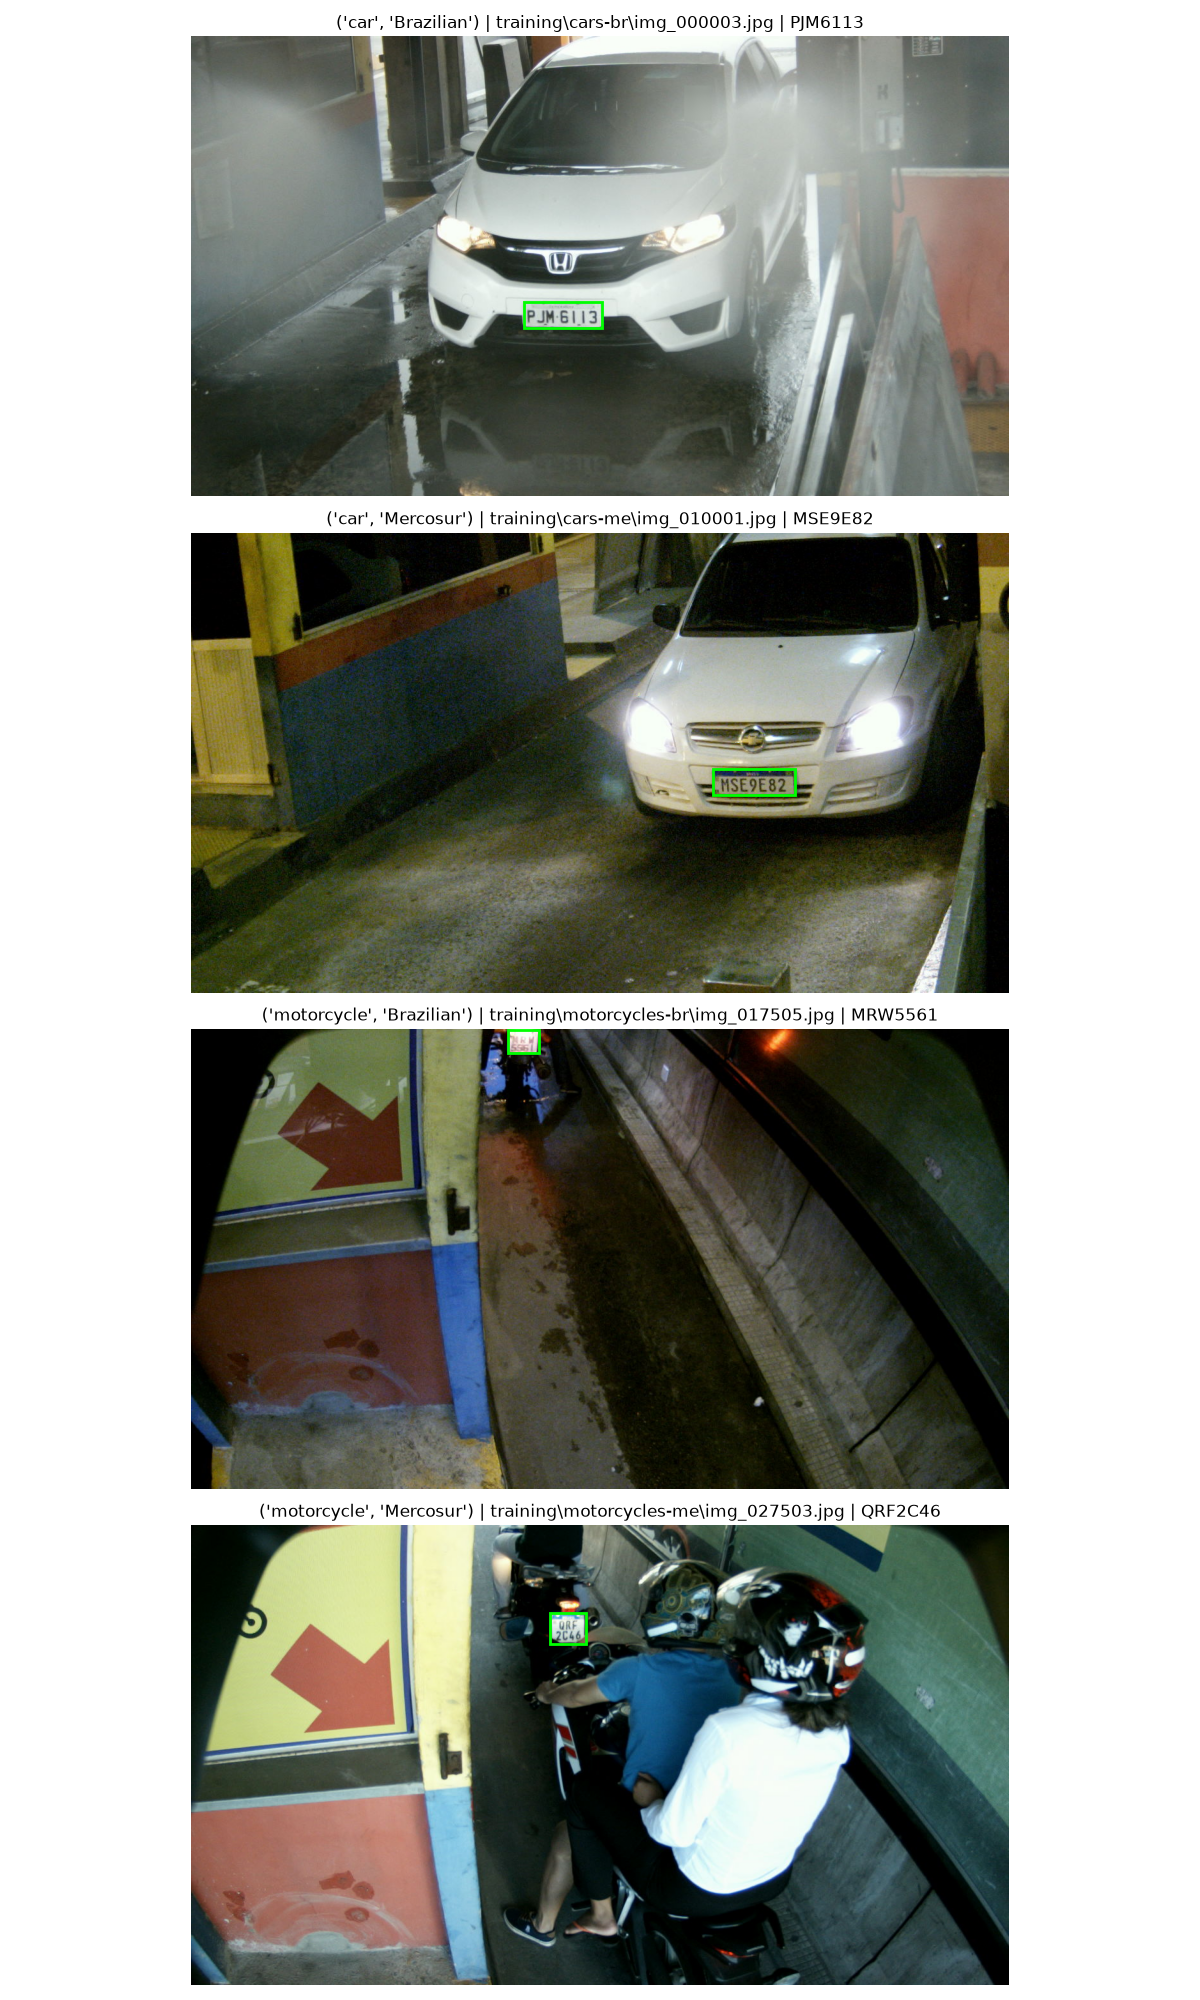

In [6]:
# Um exemplo de treino por grupo de veículo/layout ou tipo no UFPR.
amostras = {}
for r in registros:
    if r["divisao"] != "training":
        continue
    campos = ler_campos(r["imagem"].with_suffix(".txt"))
    chave = (campos.get("type"), campos.get("layout", "não informado"))
    amostras.setdefault(chave, r)
fig, eixos = plt.subplots(len(amostras), 1, figsize=(12, 5*len(amostras)), squeeze=False)
for ax, (grupo, r) in zip(eixos.flat, sorted(amostras.items())):
    with Image.open(destino / "images" / r["relativo"]) as im:
        ax.imshow(im.convert("RGB"))
    valores = [float(v) for v in (destino / "labels" / r["relativo"].with_suffix(".txt")).read_text().split()[1:]]
    cx, cy, w, h = np.array(valores) * [r["largura"], r["altura"], r["largura"], r["altura"]]
    ax.add_patch(Rectangle((cx-w/2, cy-h/2), w, h, fill=False, edgecolor="lime", linewidth=2))
    ax.set_title(f"{grupo} | {r['relativo']} | {r['placa']}")
    ax.axis("off")
fig.tight_layout()
display(fig)
plt.close(fig)


### 7. Como usar os dois datasets juntos?

Execute primeiro a preparação UFPR. O YAML combinado referencia as duas pastas. A validação agregada não substitui métricas por origem; filtros complementares de sobreposição pertencem à avaliação e não alteram estas divisões oficiais.


In [7]:
# Referenciar as duas origens sem criar uma terceira cópia das imagens.
ufpr = raiz / "datasets_yolo" / "UFPR"
if not (ufpr / "dataset.yaml").is_file():
    raise FileNotFoundError("Execute primeiro o notebook de preparação UFPR.")
config_combinada = {"path": (raiz / "datasets_yolo").as_posix(), "names": {0: "placa"}}
for chave, divisao in (("train", "training"), ("val", "validation"), ("test", "testing")):
    pastas = [ufpr / "images" / divisao, destino / "images" / divisao]
    if not all(p.is_dir() for p in pastas):
        raise FileNotFoundError(f"Pasta ausente em {divisao}")
    config_combinada[chave] = [p.as_posix() for p in pastas]
arquivo_combinado = raiz / "datasets_yolo" / "combinado.yaml"
arquivo_combinado.write_text(yaml.safe_dump(config_combinada, allow_unicode=True, sort_keys=False), encoding="utf-8")
print(arquivo_combinado.read_text(encoding="utf-8"))
print("Treino: 9.800; validação: 4.900; teste: 9.800. Avaliar também cada origem separadamente.")


path: C:/Users/igorm/Documents/programacao/modelo-placa/datasets_yolo
names:
  0: placa
train:
- C:/Users/igorm/Documents/programacao/modelo-placa/datasets_yolo/UFPR/images/training
- C:/Users/igorm/Documents/programacao/modelo-placa/datasets_yolo/RodoSol/images/training
val:
- C:/Users/igorm/Documents/programacao/modelo-placa/datasets_yolo/UFPR/images/validation
- C:/Users/igorm/Documents/programacao/modelo-placa/datasets_yolo/RodoSol/images/validation
test:
- C:/Users/igorm/Documents/programacao/modelo-placa/datasets_yolo/UFPR/images/testing
- C:/Users/igorm/Documents/programacao/modelo-placa/datasets_yolo/RodoSol/images/testing

Treino: 9.800; validação: 4.900; teste: 9.800. Avaliar também cada origem separadamente.


### Limites desta preparação

As sobreposições conhecidas foram preservadas: duas placas entre treino/teste UFPR e HDE1F59 entre treino/validação RodoSol. A avaliação complementar está documentada na estratégia. Labels representam as placas anotadas; outras placas visíveis podem não ter anotação. Geometria válida não garante anotação visualmente correta.

A escolha dos parâmetros e a execução dos três treinos são etapas posteriores.
